# 02 · Residual diagnostics

Build step 8. Out-of-fold residuals of the primary building model, r = log(1 + observed) − predicted median (positive = more buildings than expected), plus the place model where useful. Are the errors well behaved, is the 90% range calibrated across tract types, do errors drift with any input, and do they cluster in space? The last question matters twice: clustered errors break the independence that random cross-validation assumes, and the distance at which they stop being correlated tells whether 50 km blocks are large enough. No audit variable is used.

In [1]:
import warnings, os, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name in ("modelling", "notebooks", "eda") else Path.cwd()
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
TAB, FIG = Path("modelling/tables"), Path("modelling/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
cfg = yaml.safe_load(open("config/config.yaml")); mc = cfg["model"]
df = pd.read_parquet("data/processed/tracts_all.parquet")

## 1. Residual distribution

,mean,median,sd,skew,share |r| > 0.5,share below half of expected
region,,,,,,
maricopa-az,0.004,0.009,0.225,-2.761,0.035,0.008
northern-ca,-0.025,-0.011,0.158,-0.647,0.008,0.002
eastern-ok,-0.015,-0.005,0.180,-2.896,0.018,0.007
south-central-tx,-0.007,0.001,0.210,-2.026,0.021,0.007
eastern-wa,0.038,0.036,0.198,4.571,0.012,0.000
all,-0.006,0.002,0.206,-1.962,0.021,0.007


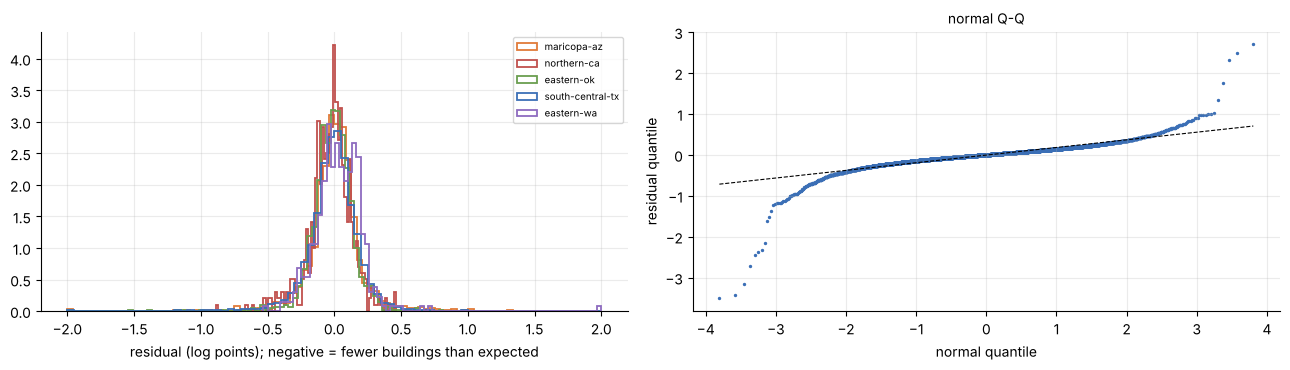

In [2]:
o = pd.read_parquet(TAB / "oof_bldg_primary.parquet").merge(df[["GEOID", "region", "county", "lat", "lon", "hu", "pop", "land_km2", "jobs", "gq_pop", "sh_u_mobile", "vacant_share", "hu_density", "ref_bldg", "r2026a_bldg450"]], on="GEOID")
o["r"] = o.y_log - o.q_med
o["region"] = pd.Categorical(o.region, REG, ordered=True)
d = o.groupby("region", observed=True).r.agg(["mean", "median", "std", "skew", lambda x: (x.abs() > .5).mean(), lambda x: (x < -np.log(2)).mean()])
d.columns = ["mean", "median", "sd", "skew", "share |r| > 0.5", "share below half of expected"]
d.loc["all"] = [o.r.mean(), o.r.median(), o.r.std(), o.r.skew(), (o.r.abs() > .5).mean(), (o.r < -np.log(2)).mean()]
d.to_csv(TAB / "02_residual_summary.csv"); display(d)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for rg in REG:
    ax[0].hist(o.loc[o.region == rg, "r"].clip(-2, 2), bins=80, histtype="step", lw=1.3, color=COL[rg], label=rg, density=True)
ax[0].set_xlabel("residual (log points); negative = fewer buildings than expected"); ax[0].legend(fontsize=7)
from scipy import stats
qq = stats.probplot(o.r, dist="norm"); ax[1].scatter(qq[0][0], qq[0][1], s=2, color="#3b6fb6"); ax[1].plot(qq[0][0], qq[1][0] * qq[0][0] + qq[1][1], "k--", lw=.8)
ax[1].set_xlabel("normal quantile"); ax[1].set_ylabel("residual quantile"); ax[1].set_title("normal Q-Q", fontsize=10)
save("02_residual_distribution")

**Takeaway.** Out-of-fold residuals are centred on zero (mean -0.006, sd 0.21 log points, about ±21%) and only 2% exceed ±0.5. They are skewed to the left in every region except eastern WA: large shortfalls are more common than large surpluses, which is the shape the method looks for. Eastern WA is shifted the other way (mean +0.04): the model under-predicts its building counts.

## 2. Is the 90% range calibrated across tract types?

,coverage,flag_rate,above_upper
region,,,
maricopa-az,0.908,0.044,0.048
northern-ca,0.932,0.049,0.019
eastern-ok,0.927,0.041,0.032
south-central-tx,0.889,0.060,0.050
eastern-wa,0.892,0.002,0.106


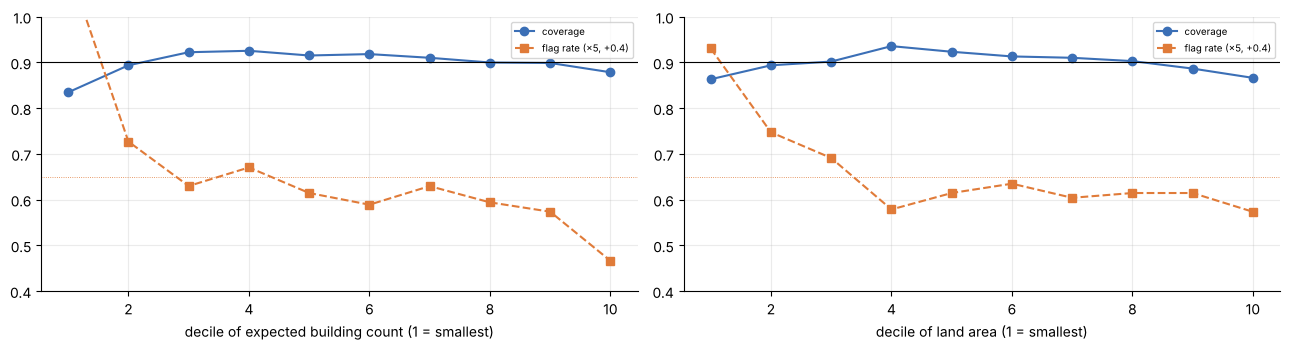

flag rate by expected-size decile: [0.142, 0.065, 0.046, 0.054, 0.043, 0.038, 0.046, 0.039, 0.035, 0.013]


In [3]:
o["size_decile"] = pd.qcut(o.expected, 10, labels=False) + 1
o["land_decile"] = pd.qcut(o.land_km2.rank(method="first"), 10, labels=False) + 1
cal = pd.concat({"expected-size decile": o.groupby("size_decile").agg(coverage=("covered", "mean"), flag_rate=("flag", "mean"), n=("r", "size")),
                 "land-area decile": o.groupby("land_decile").agg(coverage=("covered", "mean"), flag_rate=("flag", "mean"), n=("r", "size"))})
cal.to_csv(TAB / "02_calibration_by_decile.csv")
reg = o.groupby("region", observed=True).agg(coverage=("covered", "mean"), flag_rate=("flag", "mean"), above_upper=("y_log", lambda s: (s > o.loc[s.index, "upper_log"]).mean()))
display(reg.style.format("{:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, k, lab in [(ax[0], "expected-size decile", "decile of expected building count (1 = smallest)"), (ax[1], "land-area decile", "decile of land area (1 = smallest)")]:
    c = cal.loc[k]; a.plot(c.index, c.coverage, "o-", color="#3b6fb6", label="coverage"); a.plot(c.index, c.flag_rate * 5 + .4, "s--", color="#e07b39", label="flag rate (×5, +0.4)")
    a.axhline(.9, color="k", lw=.8); a.axhline(.05 * 5 + .4, color="#e07b39", lw=.6, ls=":"); a.set_xlabel(lab); a.set_ylim(.4, 1); a.legend(fontsize=7)
save("02_calibration")
print("flag rate by expected-size decile:", cal.loc["expected-size decile", "flag_rate"].round(3).tolist())

**Takeaway.** Coverage is 0.89-0.93 by region, but it is not uniform across tract types. Flags concentrate in small tracts: 14% of tracts in the smallest decile of expected count are flagged against about 4-5% in the middle and 1% in the largest, because a few missing buildings are a large share of a small count. Eastern WA has the opposite problem: almost no flags (0.2%) and 11% of tracts above the upper bound. Global CQR guarantees 90% on average, not within each size class; a size-stratified (Mondrian) calibration would even this out, and this conditional miscalibration should be stated alongside the flag results.

## 3. Do the errors drift with any input?

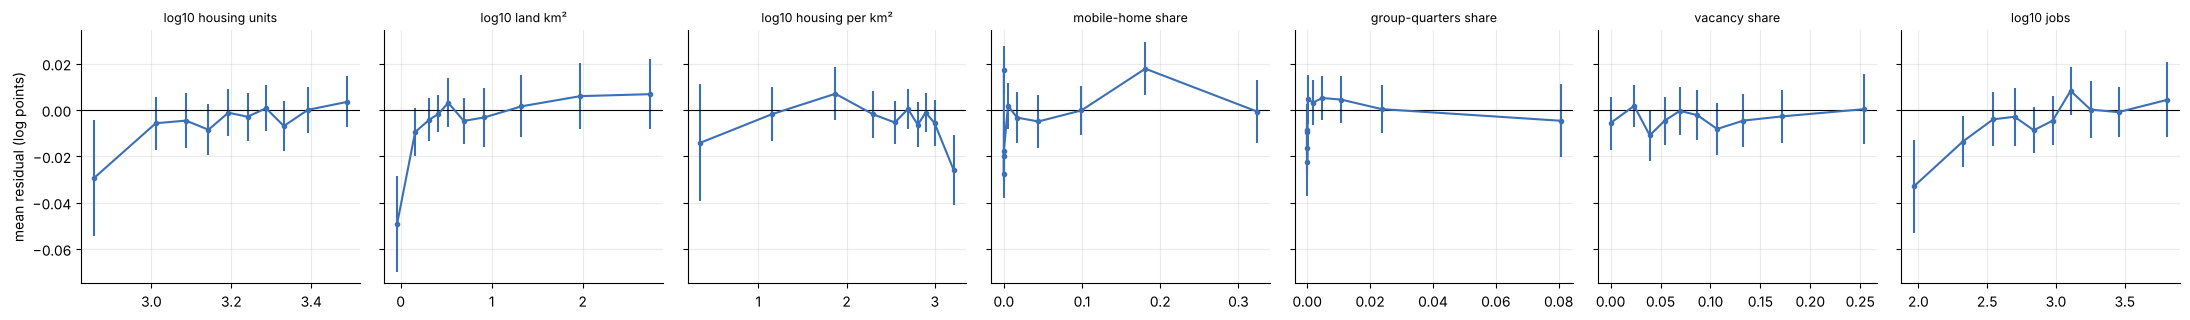

,lowest-decile mean residual,highest-decile mean residual,range of decile means
input,,,
log10 housing units,-0.030,3.452e-03,0.033
log10 land km²,-0.049,6.795e-03,0.056
log10 housing per km²,-0.014,-2.608e-02,0.033
mobile-home share,0.017,-7.148e-04,0.045
group-quarters share,-0.017,-4.674e-03,0.028
vacancy share,-0.006,3.212e-04,0.013
log10 jobs,-0.033,4.366e-03,0.041


In [4]:
X = {"log10 housing units": np.log10(o.hu + 1), "log10 land km²": np.log10(o.land_km2 + .01), "log10 housing per km²": np.log10(o.hu_density.fillna(0) + .1),
     "mobile-home share": o.sh_u_mobile, "group-quarters share": o.gq_pop / o["pop"].replace(0, np.nan), "vacancy share": o.vacant_share, "log10 jobs": np.log10(o.jobs + 1)}
fig, axs = plt.subplots(1, len(X), figsize=(22, 3.3), sharey=True); rows = []
for a, (k, v) in zip(axs, X.items()):
    b = pd.qcut(v.rank(method="first"), 10, labels=False)
    s = o.r.groupby(b).agg(["mean", "sem"]); x = v.groupby(b).median()
    a.errorbar(x, s["mean"], yerr=1.96 * s["sem"], fmt="o-", ms=3, color="#3b6fb6"); a.axhline(0, color="k", lw=.8); a.set_title(k, fontsize=9)
    rows.append({"input": k, "lowest-decile mean residual": s["mean"].iloc[0], "highest-decile mean residual": s["mean"].iloc[-1], "range of decile means": s["mean"].max() - s["mean"].min()})
axs[0].set_ylabel("mean residual (log points)"); save("02_residual_drift")
dr = pd.DataFrame(rows).set_index("input"); dr.to_csv(TAB / "02_residual_drift.csv"); display(dr)

**Takeaway.** The residuals barely drift with any input: across deciles of housing units, land area, density, mobile-home, group-quarters and vacancy shares and jobs, mean residuals stay within ±0.05 log points (about ±5%). The largest pattern is a slight over-prediction in the smallest-area tracts (-0.05). The model has no strong systematic misfit along any structural dimension.

## 4. Do errors cluster in space? (Moran's I, 8 nearest tracts within region)

In [5]:
from sklearn.neighbors import BallTree
rng = np.random.default_rng(0)
def moran(z, nb, perms=199):
    z = (z - z.mean()) / z.std(); obs = (z * z[nb].mean(axis=1)).sum() / (z ** 2).sum()
    null = np.array([(p * p[nb].mean(axis=1)).sum() / (p ** 2).sum() for p in (rng.permutation(z) for _ in range(perms))])
    return obs, (1 + (null >= obs).sum()) / (perms + 1)
poi = pd.read_parquet(TAB / "oof_poi_primary.parquet")[["GEOID", "y_log", "q_med", "flag"]].rename(columns={"y_log": "py", "q_med": "pq", "flag": "pflag"})
o = o.merge(poi, on="GEOID"); o["r_poi"] = o.py - o.pq
rows = []
for rg in REG:
    s = o[o.region == rg].reset_index(drop=True)
    nb = BallTree(np.radians(s[["lat", "lon"]].values), metric="haversine").query(np.radians(s[["lat", "lon"]].values), k=9)[1][:, 1:]
    for lab, v in [("building residual", s.r.values), ("building flag", s.flag.astype(float).values), ("place residual", s.r_poi.values)]:
        i, p = moran(v.astype(float), nb); rows.append({"region": rg, "quantity": lab, "moran_I": i, "perm_p": p})
mi = pd.DataFrame(rows).pivot(index="region", columns="quantity", values="moran_I").reindex(REG)
mi.to_csv(TAB / "02_moran.csv"); display(mi.style.format("{:.3f}"))
print("all permutation p-values:", sorted(set(np.round([r["perm_p"] for r in rows], 3))))

quantity,building flag,building residual,place residual
region,,,
maricopa-az,0.060,0.113,0.092
northern-ca,0.074,0.180,0.171
eastern-ok,0.057,0.156,0.064
south-central-tx,0.082,0.151,0.146
eastern-wa,-0.003,0.088,0.127


all permutation p-values: [np.float64(0.005), np.float64(0.775)]


**Takeaway.** Errors do cluster in space: Moran's I of the building residuals is 0.09-0.18 in every region, all significant (permutation p = 0.005), and similar for places. Flags cluster more weakly (0.06-0.08; none in eastern WA, where there are almost no flags). Neighbouring tracts share unmeasured local factors, such as mapping campaigns or building styles, so random cross-validation would overstate accuracy, which is why the model is cross-fitted over spatial blocks.

## 5. How far does the correlation reach, compared with the 50 km blocks?

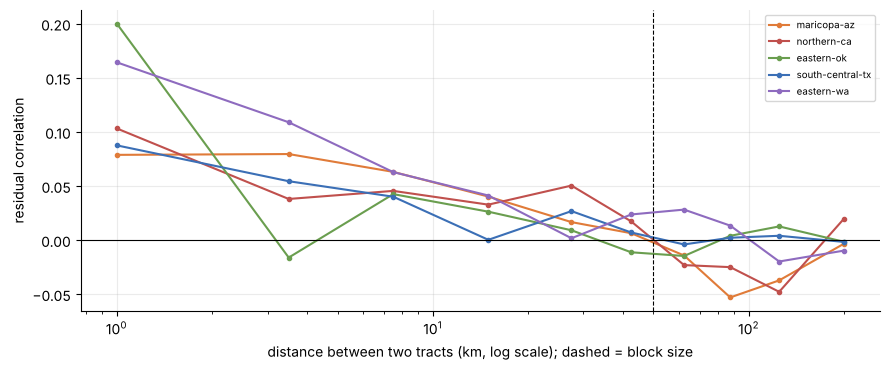

region,maricopa-az,northern-ca,eastern-ok,south-central-tx,eastern-wa
mid_km,,,,,
1.000000,0.079,0.103,0.200,0.088,0.164
3.500000,0.080,0.038,-0.016,0.054,0.109
7.500000,0.063,0.046,0.043,0.040,0.063
15.000000,0.040,0.033,0.026,0.000,0.041
27.500000,0.017,0.050,0.009,0.027,0.002
42.500000,0.006,0.017,-0.011,0.007,0.024
62.500000,-0.014,-0.023,-0.015,-0.004,0.028
87.500000,-0.053,-0.025,0.004,0.002,0.013
125.000000,-0.037,-0.048,0.013,0.004,-0.020


In [6]:
EDGES = [0, 2, 5, 10, 20, 35, 50, 75, 100, 150, 250]
rows = []
for rg in REG:
    s = o[o.region == rg]; n = len(s)
    i, j = rng.integers(0, n, 400_000), rng.integers(0, n, 400_000); k = i != j; i, j = i[k], j[k]
    la, lo = np.radians(s.lat.values), np.radians(s.lon.values)
    dkm = 6371 * 2 * np.arcsin(np.sqrt(np.sin((la[i] - la[j]) / 2) ** 2 + np.cos(la[i]) * np.cos(la[j]) * np.sin((lo[i] - lo[j]) / 2) ** 2))
    z = ((s.r - s.r.mean()) / s.r.std()).values
    b = pd.cut(dkm, EDGES)
    g = pd.DataFrame({"b": b, "p": z[i] * z[j]}).groupby("b", observed=True).p.agg(["mean", "size"])
    g["region"] = rg; rows.append(g.reset_index())
dc = pd.concat(rows); dc["mid_km"] = dc.b.apply(lambda x: (x.left + x.right) / 2)
dc.to_csv(TAB / "02_distance_decay.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
for rg in REG:
    s = dc[(dc.region == rg) & (dc["size"] >= 200)]; ax.plot(s.mid_km, s["mean"], "o-", ms=3, color=COL[rg], label=rg)
ax.axhline(0, color="k", lw=.8); ax.axvline(mc["spatial_block_km"], color="k", ls="--", lw=.8); ax.set_xscale("log")
ax.set_xlabel("distance between two tracts (km, log scale); dashed = block size"); ax.set_ylabel("residual correlation"); ax.legend(fontsize=7)
save("02_distance_decay")
w = dc[dc["size"] >= 200].pivot_table(index="mid_km", columns="region", values="mean")[REG]; display(w.style.format("{:.3f}"))

**Takeaway.** The residual correlation is highest between tracts within a few kilometres (about 0.1-0.2), falls below 0.03 by 25-45 km and is near zero beyond 50 km in four regions; eastern WA keeps a small correlation (about 0.03) out to roughly 60 km. The 50 km spatial blocks are therefore large enough to separate training and test tracts almost everywhere, and the 25 km and 100 km variants in 01 confirm that the block size changes nothing material.

## 6. Where are the residuals?

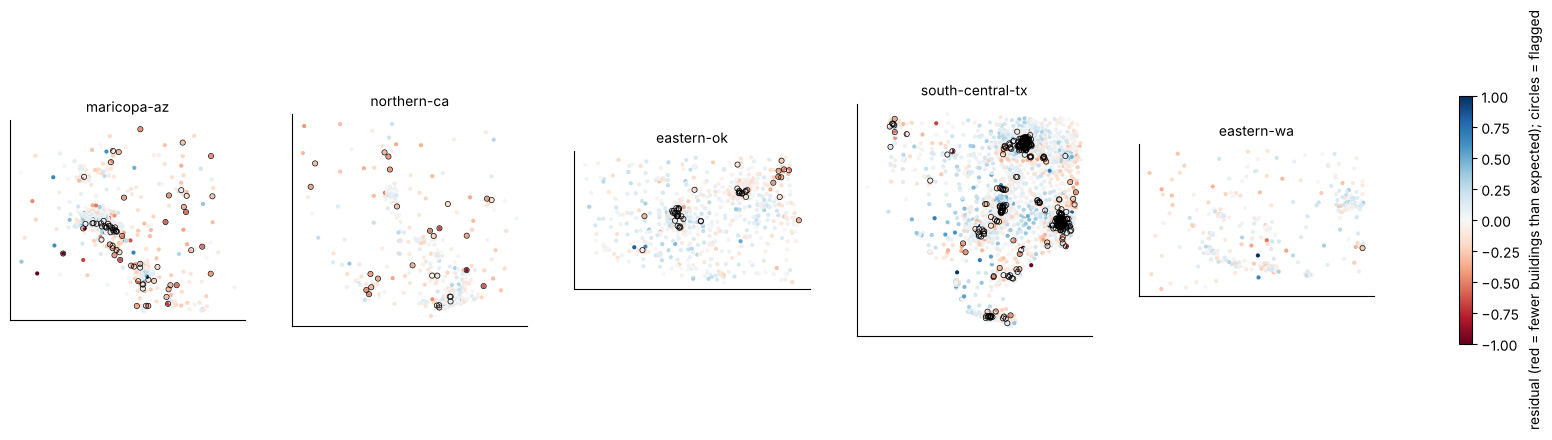

In [7]:
fig, axs = plt.subplots(1, 5, figsize=(22, 4.6))
for a, rg in zip(axs, REG):
    s = o[o.region == rg]; sc = a.scatter(s.lon, s.lat, c=s.r.clip(-1, 1), cmap="RdBu", vmin=-1, vmax=1, s=4)
    a.scatter(s.lon[s.flag], s.lat[s.flag], facecolors="none", edgecolors="k", s=14, lw=.5); a.set_title(rg, fontsize=10); a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.colorbar(sc, ax=axs, shrink=.7, label="residual (red = fewer buildings than expected); circles = flagged")
plt.savefig(FIG / "02_residual_maps.png", dpi=130, bbox_inches="tight"); plt.show()

**Takeaway.** Flags (circles) are not spread evenly: they bunch in the dense clusters of small tracts that make up the metropolitan areas (most visibly in south-central Texas, and along the urban corridors of Maricopa and eastern Oklahoma), while rural tracts have fewer flags and more scattered residuals. This matches section 2 (flags concentrate in small tracts) and section 4 (short-range clustering). These maps use the 2026-08 release, so the 2026-10 San Antonio drop is not in them. The maps show tract centroids without a basemap, so they locate patterns roughly, not individual neighbourhoods.

## Summary

The building model's errors are small, centred and without strong drift, and their spatial correlation dies out within the 50 km block size. Two caveats belong in the paper: the 90% range is not equally calibrated across tract sizes (flags concentrate in small tracts, almost none in eastern WA), and errors cluster spatially at short range, so neighbouring flags are not independent evidence.